In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import RAW_DATA_DIR, dataset_overview, load_csv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 1. Load both files

In [3]:
fake_raw = load_csv(RAW_DATA_DIR / "Fake.csv")
real_raw = load_csv(RAW_DATA_DIR / "True.csv")
print("Fake:", fake_raw.shape, "| Real:", real_raw.shape)
fake_raw.head(3)

Fake: (23481, 4) | Real: (21417, 4)


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,"Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout...",News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,"House Intelligence Committee Chairman Devin Nunes is going to have a bad day. He s been under the assumption, like m...",News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,"On Friday, it was revealed that former Milwaukee Sheriff David Clarke, who was being considered for Homeland Securit...",News,"December 30, 2017"


## 2. Data types and missing values

In [4]:
for name, df in [("FAKE", fake_raw), ("REAL", real_raw)]:
    print(f"--- {name} ---")
    print(df.dtypes)
    print("Missing values per column:")
    print(df.isna().sum())
    print()

--- FAKE ---
title      str
text       str
subject    str
date       str
dtype: object
Missing values per column:
title      0
text       0
subject    0
date       0
dtype: int64

--- REAL ---
title      str
text       str
subject    str
date       str
dtype: object
Missing values per column:
title      0
text       0
subject    0
date       0
dtype: int64



## 3. Duplicate records

Exact duplicates are counted within each file. Duplicates across the two
files are also checked, because an article labelled both fake and real is a
data-quality problem.

In [5]:
print("Duplicate rows within FAKE:", int(fake_raw.duplicated().sum()))
print("Duplicate rows within REAL:", int(real_raw.duplicated().sum()))

overlap = pd.merge(fake_raw[["title", "text"]], real_raw[["title", "text"]], on=["title", "text"])
print("Articles appearing in BOTH files:", len(overlap))

Duplicate rows within FAKE: 3
Duplicate rows within REAL: 206
Articles appearing in BOTH files: 0


## 4. Class distribution

label  count
 fake  23481
 real  21417


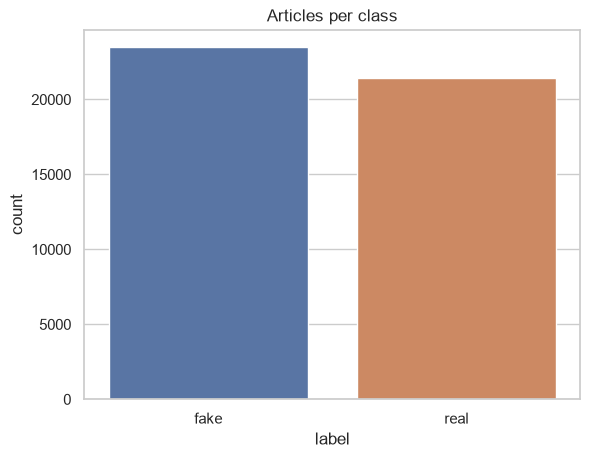

In [6]:
counts = pd.DataFrame({
    "label": ["fake", "real"],
    "count": [len(fake_raw), len(real_raw)],
})
print(counts.to_string(index=False))

sns.barplot(data=counts, x="label", y="count", hue="label", legend=False)
plt.title("Articles per class")
plt.show()

## 5. Article length

         count   mean    std  min    25%    50%    75%     max
label                                                         
fake   23481.0  423.2  408.4  0.0  240.0  363.0  506.0  8135.0
real   21417.0  385.6  274.0  0.0  148.0  359.0  525.0  5172.0


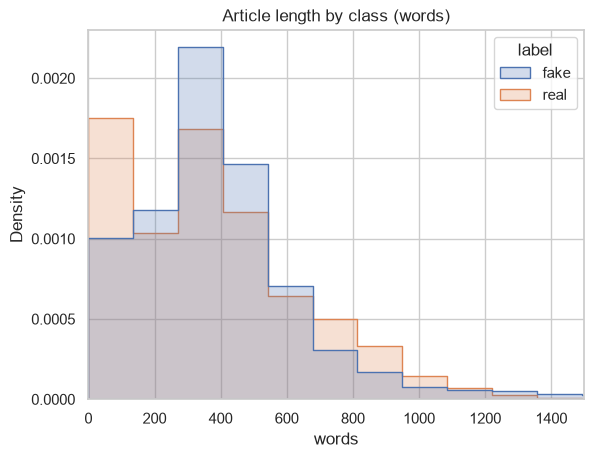

In [7]:
fake_len = fake_raw["text"].fillna("").str.split().str.len().rename("words").to_frame().assign(label="fake")
real_len = real_raw["text"].fillna("").str.split().str.len().rename("words").to_frame().assign(label="real")
lengths = pd.concat([fake_len, real_len], ignore_index=True)

print(lengths.groupby("label")["words"].describe().round(1))

sns.histplot(data=lengths, x="words", hue="label", bins=60, element="step", stat="density", common_norm=False)
plt.xlim(0, 1500)
plt.title("Article length by class (words)")
plt.show()

## 6. Subject column

In [8]:
if "subject" in fake_raw.columns and "subject" in real_raw.columns:
    print("FAKE subjects:")
    print(fake_raw["subject"].value_counts())
    print("\nREAL subjects:")
    print(real_raw["subject"].value_counts())
    print("\nSubjects shared by both classes:", sorted(set(fake_raw["subject"]) & set(real_raw["subject"])))

FAKE subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

REAL subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64

Subjects shared by both classes: []
